# Phase 3B | Uncertainty-Aware Hybrid Neural Digital Twin

**Real neural data:** DANDI **000568**, version **0.230705.1633**. Two recording sessions from **the same mouse** (`fCamk1`).

**Experiment:** Predict spontaneous (light-free) population firing rates at four horizons (**0.1, 1, 3, 6 seconds**). Compare persistence, a leaky biological baseline, a GRU deep ensemble, and a leaky-dynamics + GRU-residual deep ensemble. Calibrate **nominal 90% prediction intervals** on chronologically separate training-session data and evaluate on a fully held-out session.

**Keep the evidence boundary clear:**
- **REAL:** one-step / multi-horizon errors, free-running rollouts, interval coverage/width, and high-activity errors on observed sorted spikes. These are **mouse** neural-rate results, not epilepsy or treatment outcomes.
- **HYPOTHETICAL:** light-response sensitivity examples (a *chosen*, unmeasured optical coefficient). These are model sanity checks, **not evidence of observed optical modulation**.
- **Not supported:** human personalization, cross-animal generalization, clinical safety, calibrated light-dose response, or effective therapeutic control.

The two sessions are biologically **one animal**. Time bins are correlated, and split-conformal coverage guarantees do **not** transfer automatically from one recording session to another. We report empirical coverage, not a claimed coverage guarantee.

**Kaggle settings:** Internet ON, Accelerator None (CPU sufficient), no attached Kaggle input. Start with `QUICK_MODE=True`. Results ZIP: `phase3b_uncertainty_digital_twin_results.zip`.

## 1. Install imports and configure the real-data experiment

In quick mode we use **3 independent random initializations per model family**, **8 training epochs**, and capped examples. The larger run uses 5 models per family and 25 epochs. This may take several minutes on CPU. No simulated observations substitute for real DANDI recordings.

In [1]:
import sys, importlib.util, subprocess
for package, module in [('requests','requests'),('h5py','h5py'),('numpy','numpy'),('pandas','pandas'),
                        ('scipy','scipy'),('matplotlib','matplotlib'),('scikit-learn','sklearn'),('torch','torch')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable,'-m','pip','install','-q',package])

import copy, json, zipfile, re, random, math, warnings
from pathlib import Path
from datetime import datetime, timezone
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests, h5py
from scipy.ndimage import binary_dilation
from scipy.stats import spearmanr
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED=20261013
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
torch.set_num_threads(2)
QUICK_MODE=True
USE_GPU=False  # Avoid queuing for a GPU; toggle only when needed
DEVICE=torch.device('cuda' if USE_GPU and torch.cuda.is_available() else 'cpu')
DANDISET='000568';VERSION='0.230705.1633';BASE='https://api.dandiarchive.org'
BIN_SEC=0.1; HISTORY_BINS=20
HORIZONS=np.array([1,10,30,60],dtype=int)  # 100 ms, 1 s, 3 s, 6 s
HORIZON_NAMES=['0.1s','1s','3s','6s']
MAX_H=int(HORIZONS.max())
LIGHT_GUARD_SEC=0.3
STRIDE_BINS=10  # 1-second anchor spacing; still correlated outcomes
N_ENSEMBLE=3 if QUICK_MODE else 5
EPOCHS=8 if QUICK_MODE else 25
BATCH_SIZE=128
CAPS=({'train':2400,'val':400,'calib':400,'test':900} if QUICK_MODE else
      {'train':11000,'val':1700,'calib':1700,'test':3300})
N_ROLLOUT_SEGMENTS=8 if QUICK_MODE else 20
BLOCK_BOOTSTRAP_REPS=250 if QUICK_MODE else 1000
ALPHA=0.10
ROOT=Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('/mnt/data')
OUT=ROOT/'phase3b_outputs';CACHE=ROOT/'phase3b_nwb_cache'
OUT.mkdir(parents=True,exist_ok=True);CACHE.mkdir(parents=True,exist_ok=True)
FOLDS=[('session_9','session_12'),('session_12','session_9')]
print('Device:',DEVICE,'Quick:',QUICK_MODE,'Ensemble per family:',N_ENSEMBLE)
print('Forecast horizons (sec):',HORIZONS*BIN_SEC)
print('OUTPUT:',OUT)

Device: cpu Quick: True Ensemble per family: 3
Forecast horizons (sec): [0.1 1.  3.  6. ]
OUTPUT: /kaggle/working/phase3b_outputs


## 2. Download two version-pinned, small `+ogen` NWB files

Both files are expected to total ~73 MB. They contain sorted spike times and recorded optical commands. We **exclude light epochs** from the spontaneous-rate predictor and **do not interpret uncalibrated optical numeric codes as watts**.

In [2]:
def api_json(url):
    r=requests.get(url,timeout=(20,80),headers={'Accept':'application/json'})
    r.raise_for_status();return r.json()
assets=[];url=f'{BASE}/api/dandisets/{DANDISET}/versions/{VERSION}/assets/'
while url:
    d=api_json(url)
    assets.extend(d['results']);url=d.get('next')
manifest=pd.DataFrame([{'asset_id':a['asset_id'],'path':a['path'],'size_bytes':int(a['size'])} for a in assets])
selected=manifest[manifest.path.str.endswith('.nwb') &
                  manifest.path.str.contains('+ogen',regex=False) &
                  manifest.path.str.contains('no-raw-data',regex=False) &
                  (manifest.size_bytes<70_000_000)].sort_values('size_bytes').copy()
if len(selected)!=2:raise RuntimeError(f'Expected 2 small optogenetic files, found {len(selected)}')
selected.to_csv(OUT/'REAL_manifest_pinned.csv',index=False)

def download_asset(row):
    expected=int(row['size_bytes'])
    if expected>70_000_000:raise RuntimeError('Oversize asset blocked')
    path=CACHE/Path(row['path']).name
    if path.exists() and path.stat().st_size==expected:return path
    part=path.with_name(path.name+'.part')
    with requests.get(f"{BASE}/api/assets/{row['asset_id']}/download/",stream=True,timeout=(30,180)) as response:
        response.raise_for_status()
        with part.open('wb') as stream:
            for block in response.iter_content(chunk_size=1_048_576):
                if block:stream.write(block)
    if part.stat().st_size!=expected:raise IOError('Downloaded asset size mismatch')
    part.replace(path);print('Downloaded',path.name,round(expected/1e6,2),'MB')
    return path
session_files={}
for _,row in selected.iterrows():
    m=re.search(r'sess(\d+)',row['path'])
    if not m:raise RuntimeError('Missing session name: '+row['path'])
    session_files['session_'+m.group(1)]=download_asset(row)
assert set(session_files)=={'session_9','session_12'}
print('Using sessions:',sorted(session_files))

Downloaded sub-fCamk1_ses-fCamk1-200901-sess12-no-raw-data_behavior+ecephys+image+ogen.nwb 28.68 MB
Downloaded sub-fCamk1_ses-fCamk1-200827-sess9-no-raw-data_behavior+ecephys+image+ogen.nwb 44.44 MB
Using sessions: ['session_12', 'session_9']


## 3. Load **real** sorted spikes and exclude light / nearby windows

All neural rates are **Hz per sorted neural unit**: the total sorted spike count per 100-ms bin divided by the number of units and 0.1 s. Models never see future recorded neural activity as input.

In [3]:
def read_light_events(hf,label):
    root=hf.get('/stimulus/presentation')
    if root is None:raise RuntimeError('Missing stimulus/presentation group')
    rows=[]
    for name,g in root.items():
        if not isinstance(g,h5py.Group) or not name.startswith('OptogeneticSeriesSite'):
            continue
        if 'data' not in g or 'timestamps' not in g:continue
        t=np.asarray(g['timestamps'][:],dtype=float)
        v=np.asarray(g['data'][:],dtype=float).reshape(-1)
        if len(t)!=len(v) or len(t)<3 or np.any(np.diff(t)<0):continue
        on=np.isfinite(v)&(v>0)
        starts=np.flatnonzero(on&~np.r_[False,on[:-1]])
        stops=np.flatnonzero(~on&np.r_[False,on[:-1]])
        if on[0]:starts=starts[1:]
        ix=np.searchsorted(stops,starts,side='right')
        for st,i in zip(starts,ix):
            if i>=len(stops):continue
            en=stops[i]
            if np.isfinite(t[st]) and np.isfinite(t[en]) and 0<=t[st]<t[en]:
                rows.append({'session':label,'site':name,'on_sec':float(t[st]),
                             'off_sec':float(t[en]),'duration_sec':float(t[en]-t[st])})
    if not rows:raise RuntimeError('No complete optical-command intervals found in '+label)
    return pd.DataFrame(rows)

def light_overlap_mask(events,n):
    delta=np.zeros(n+1,dtype=np.int32)
    st=np.floor(events.on_sec.to_numpy()/BIN_SEC).astype(int)
    ed=np.floor(np.nextafter(events.off_sec.to_numpy(),-np.inf)/BIN_SEC).astype(int)
    ok=(st>=0)&(st<n)&(ed>=st)
    st=st[ok];ed=np.minimum(ed[ok],n-1)
    np.add.at(delta,st,1);np.add.at(delta,ed+1,-1)
    return np.cumsum(delta[:-1])>0

def load_real_session(label,path):
    with h5py.File(path,'r') as hf:
        if '/units/spike_times' not in hf or '/units/spike_times_index' not in hf:
            raise RuntimeError('No sorted spikes in '+label)
        spikes=np.asarray(hf['/units/spike_times'][:],dtype=np.float64)
        n_units=len(hf['/units/spike_times_index'])
        events=read_light_events(hf,label)
    spikes=spikes[np.isfinite(spikes)&(spikes>=0)]
    if not len(spikes) or not n_units:raise RuntimeError('Empty neural recording')
    if events.on_sec.min()<spikes.min() or events.on_sec.max()>spikes.max():
        raise RuntimeError('Optical event/spike time ranges do not overlap safely')
    n=int(np.ceil(max(spikes.max(),events.off_sec.max())/BIN_SEC))+1
    counts=np.bincount(np.floor(spikes/BIN_SEC).astype(np.int64),minlength=n)
    rate=np.asarray(counts/(n_units*BIN_SEC),dtype=np.float32)
    light=light_overlap_mask(events,n)
    guard=max(1,int(math.ceil(LIGHT_GUARD_SEC/BIN_SEC)))
    near_light=binary_dilation(light,structure=np.ones(2*guard+1,dtype=bool))
    return {'session':label,'rate':rate,'near_light':near_light,'light':light,
            'events':events,'n_units':n_units,'n_spikes':len(spikes),'n_bins':n}

sessions={k:load_real_session(k,v) for k,v in sorted(session_files.items())}
inv=pd.DataFrame([{'session':s['session'],'n_units':s['n_units'],'n_spikes':s['n_spikes'],
                   'n_optical_commands':len(s['events']),'recording_seconds':s['n_bins']*BIN_SEC,
                   'guarded_light_free_fraction':float(np.mean(~s['near_light']))}
                  for s in sessions.values()])
inv.to_csv(OUT/'REAL_recording_inventory.csv',index=False)
print(inv.to_string(index=False))

   session  n_units  n_spikes  n_optical_commands  recording_seconds  guarded_light_free_fraction
session_12       47   1800735               50309            14810.3                     0.549739
 session_9       57   2259343               42088            17920.2                     0.758898


## 4. Leakage-aware chronology and multi-horizon neural targets

For each fold, the **training session** is separated chronologically into **train (0–55%)**, **validation (61–72%)**, and **calibration (78–90%)**, with unassigned gaps. The *other entire recording session* is the test set. Each eligible example must have a 2-second neural history **and all six seconds of future evaluation** outside guarded light epochs.

The calibration period is **never** used to fit or select neural-network weights. Correlated windows remain correlated, and two sessions from one mouse are not independent biological subjects.

In [4]:
def sample_anchors(s,begin,end,max_count,seed):
    n=s['n_bins'];start=max(HISTORY_BINS+1,int(begin));stop=min(int(end),n-MAX_H-1)
    if stop<=start:raise RuntimeError('Split too short: '+s['session'])
    anchor=np.arange(start,stop,STRIDE_BINS,dtype=np.int64)
    bad=np.r_[0,np.cumsum(s['near_light'].astype(np.int64))]
    eligible=(bad[anchor+MAX_H]-bad[anchor-HISTORY_BINS])==0
    anchor=anchor[eligible]
    if len(anchor)<25:raise RuntimeError(f'Too few eligible light-free anchors in {s["session"]}: {len(anchor)}')
    if len(anchor)>max_count:
        anchor=np.sort(np.random.default_rng(seed).choice(anchor,size=max_count,replace=False))
    return anchor

def make_examples(s,anchor):
    a=np.asarray(anchor,dtype=np.int64)
    ix=a[:,None]-HISTORY_BINS+np.arange(HISTORY_BINS)[None,:]
    x=s['rate'][ix].astype(np.float32)
    y=s['rate'][a[:,None]+HORIZONS[None,:]-1].astype(np.float32)
    return {'X':x,'y':y,'last':x[:,-1],'anchor':a,'time_sec':a*BIN_SEC,
            'session':s['session']}

def make_fold(train_s,test_s,seed):
    n=train_s['n_bins']
    train=make_examples(train_s,sample_anchors(train_s,0,0.55*n,CAPS['train'],seed))
    val=make_examples(train_s,sample_anchors(train_s,0.61*n,0.72*n,CAPS['val'],seed+1))
    calib=make_examples(train_s,sample_anchors(train_s,0.78*n,0.90*n,CAPS['calib'],seed+2))
    test=make_examples(test_s,sample_anchors(test_s,0,test_s['n_bins'],CAPS['test'],seed+3))
    for earlier,later in [(train,val),(val,calib)]:
        assert earlier['anchor'].max()+MAX_H+HISTORY_BINS < later['anchor'].min()
    assert train['session']==val['session']==calib['session']!=test['session']
    return {'train':train,'val':val,'calib':calib,'test':test}

def leaky_fit(ex):
    last=np.asarray(ex['last'],dtype=float)
    y=np.asarray(ex['y'][:,0],dtype=float)
    mu=float(np.mean(y));den=np.sum((last-mu)**2)
    alpha=float(np.sum((last-mu)*(y-mu))/den) if den>1e-10 else 0.
    return {'mu_Hz':mu,'alpha':float(np.clip(alpha,0,.995)),'n_train':len(y)}

def leaky_multihorizon(last,fit):
    last=np.asarray(last,dtype=float).reshape(-1,1)
    return np.maximum(0.,fit['mu_Hz']+
                      (fit['alpha']**HORIZONS.reshape(1,-1))*(last-fit['mu_Hz']))

## 5. Models: direct multi-horizon GRU and biology-inspired GRU-residual

Both neural networks have the **same architecture, training data, optimizer, and loss**. Their only difference is the target representation:

- **GRU:** predicts neural firing rates for each horizon.
- **Hybrid GRU:** learns a correction to a nonnegative leaky population-rate baseline.

Training uses multi-horizon Huber loss on standardized log firing rates. Every result is computed on observed recordings **with light excluded**. Member variance is a disagreement indicator; **it is not automatically a calibrated uncertainty estimate**.

In [5]:
class MultiHorizonGRU(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn=nn.GRU(input_size=1,hidden_size=32,batch_first=True)
        self.head=nn.Sequential(nn.Linear(32,32),nn.Tanh(),nn.Linear(32,len(HORIZONS)))
    def forward(self,x):
        _,h=self.rnn(x)
        return self.head(h[-1])

def fit_scaler(train,kind,params):
    logx=np.log1p(train['X'])
    tgt=np.log1p(train['y'])
    if kind=='Hybrid_GRU':tgt=tgt-np.log1p(leaky_multihorizon(train['last'],params))
    return {'x_mu':float(logx.mean()),'x_sd':max(float(logx.std()),.03),
            'target_mu':np.mean(tgt,axis=0).tolist(),
            'target_sd':np.maximum(np.std(tgt,axis=0),.03).tolist()}

def model_features(ex,sc):
    return ((np.log1p(ex['X'])-sc['x_mu'])/sc['x_sd']).astype(np.float32)[:,:,None]

def model_targets(ex,sc,kind,params):
    tgt=np.log1p(ex['y'])
    if kind=='Hybrid_GRU':tgt=tgt-np.log1p(leaky_multihorizon(ex['last'],params))
    return ((tgt-np.array(sc['target_mu']))/np.array(sc['target_sd'])).astype(np.float32)

def train_member(train,val,kind,params,sc,seed):
    torch.manual_seed(seed)
    x=model_features(train,sc);y=model_targets(train,sc,kind,params)
    vx=torch.from_numpy(model_features(val,sc)).to(DEVICE)
    vy=torch.from_numpy(model_targets(val,sc,kind,params)).to(DEVICE)
    loader=DataLoader(TensorDataset(torch.from_numpy(x),torch.from_numpy(y)),
                      batch_size=BATCH_SIZE,shuffle=True,num_workers=0)
    model=MultiHorizonGRU().to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=.002,weight_decay=2e-4)
    weights=torch.tensor([.35,.25,.20,.20],dtype=torch.float32,device=DEVICE)
    def loss_fn(pred,target):
        el=nn.functional.smooth_l1_loss(pred,target,reduction='none')
        return (el*weights).sum(axis=1).mean()
    best=float('inf');state=None;bad=0;trace=[]
    for epoch in range(EPOCHS):
        model.train();total=0.;n=0
        for bx,by in loader:
            bx=bx.to(DEVICE);by=by.to(DEVICE)
            opt.zero_grad();pred=model(bx);loss=loss_fn(pred,by)
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.0)
            opt.step();total+=float(loss.item())*len(by);n+=len(by)
        model.eval()
        with torch.no_grad():
            vparts=[model(vx[i:i+BATCH_SIZE]) for i in range(0,len(vx),BATCH_SIZE)]
            vl=float(loss_fn(torch.cat(vparts),vy).item())
        trace.append({'epoch':epoch+1,'train_loss':total/max(1,n),'val_loss':vl})
        if vl<best-1e-4:best=vl;state=copy.deepcopy(model.state_dict());bad=0
        else:
            bad+=1
            if bad>=5:break
    if state is not None:model.load_state_dict(state)
    return model.cpu().eval(),pd.DataFrame(trace)

@torch.no_grad()
def predict_member(model,ex,sc,kind,params):
    model=model.to(DEVICE).eval()
    x=model_features(ex,sc);raw=[]
    for j in range(0,len(x),BATCH_SIZE):
        raw.append(model(torch.from_numpy(x[j:j+BATCH_SIZE]).to(DEVICE)).cpu().numpy())
    raw=np.concatenate(raw,axis=0)
    z=raw*np.array(sc['target_sd'])+np.array(sc['target_mu'])
    if kind=='Hybrid_GRU':
        z=z+np.log1p(leaky_multihorizon(ex['last'],params))
    return np.expm1(np.clip(z,0,np.log1p(500.))).astype(np.float32)

@torch.no_grad()
def predict_ensemble(models,ex,sc,kind,params):
    members=np.stack([predict_member(m,ex,sc,kind,params) for m in models],axis=0)
    return members.mean(axis=0),members.std(axis=0,ddof=1),members

def metrics(y,pred):
    y=np.asarray(y,dtype=float);pred=np.asarray(pred,dtype=float)
    mae=float(mean_absolute_error(y,pred));rmse=float(np.sqrt(mean_squared_error(y,pred)))
    return {'MAE_Hz':mae,'MSE_Hz2':float(mean_squared_error(y,pred)),
            'RMSE_Hz':rmse,'R2':float(r2_score(y,pred)) if len(y)>1 else np.nan,
            'Bias_Hz':float(np.mean(pred-y)),
            'P90_AE_Hz':float(np.quantile(np.abs(pred-y),.90))}

## 6. Two session-held-out folds, ensemble training, and honest baseline comparisons

The **trained-network hyperparameters are fixed** before inspecting held-out test performance. Separate validation controls early stopping; calibration controls interval width. The two test folds reuse the **same mouse** and therefore must not be presented as biological replication.

In [6]:
SAVED={};METRICS=[];PREDICTIONS=[];CURVES=[];SPLITS=[];PARAMS=[];PEAK_ROWS=[]
for fold,(train_label,test_label) in enumerate(FOLDS,1):
    print('\n'+'='*20,'FOLD',fold,train_label,'->',test_label,'='*20,flush=True)
    data=make_fold(sessions[train_label],sessions[test_label],SEED+fold*31)
    for split_name,ex in data.items():
        SPLITS.append({'fold':fold,'split':split_name,'session':ex['session'],
                       'n_examples':len(ex['y']),
                       'first_anchor_sec':float(ex['time_sec'].min()),
                       'last_anchor_sec':float(ex['time_sec'].max()),
                       'full_6s_light_free':True})
    params=leaky_fit(data['train'])
    PARAMS.append({'fold':fold,'train_session':train_label,'heldout_session':test_label,**params})
    record={'fold':fold,'train_session':train_label,'test_session':test_label,
            'params':params,'splits':data,'families':{}}
    for kind in ['GRU','Hybrid_GRU']:
        sc=fit_scaler(data['train'],kind,params)
        members=[]
        for member in range(N_ENSEMBLE):
            seed=SEED+fold*1000+member*23+(0 if kind=='GRU' else 500)
            model,curve=train_member(data['train'],data['val'],kind,params,sc,seed)
            curve['fold']=fold;curve['model']=kind;curve['seed']=seed
            CURVES.append(curve)
            members.append(model)
            torch.save({'state_dict':model.state_dict(),'kind':kind,'seed':seed,
                        'scaler':sc,'leaky':params,'horizons_bins':HORIZONS.tolist(),
                        'train_session':train_label,'heldout_session':test_label},
                       OUT/f'REAL_fold{fold}_{kind}_member{member+1}.pt')
        cmean,cstd,_=predict_ensemble(members,data['calib'],sc,kind,params)
        tmean,tstd,_=predict_ensemble(members,data['test'],sc,kind,params)
        record['families'][kind]={'models':members,'scaler':sc,'calib_mean':cmean,
                                   'calib_std':cstd,'test_mean':tmean,'test_std':tstd}
        print(kind,'test MAE by horizon:',
              [round(float(mean_absolute_error(data['test']['y'][:,h],tmean[:,h])),3)
               for h in range(len(HORIZONS))],flush=True)
    test=data['test'];y=test['y']
    base={'Persistence':np.repeat(test['last'][:,None],len(HORIZONS),axis=1),
          'Leaky_Dynamics':leaky_multihorizon(test['last'],params),
          'GRU_ensemble':record['families']['GRU']['test_mean'],
          'Hybrid_GRU_ensemble':record['families']['Hybrid_GRU']['test_mean']}
    peak_cut=np.quantile(data['train']['y'],.90,axis=0)
    for h,name in enumerate(HORIZON_NAMES):
        high=(y[:,h]>=peak_cut[h])
        for model_name,p in base.items():
            for subgroup,mask in [('ALL',np.ones(len(y),dtype=bool)),
                                  ('HIGH_ACTIVITY',high),('OTHER_ACTIVITY',~high)]:
                if int(mask.sum())<2:continue
                METRICS.append({'fold':fold,'heldout_session':test_label,'horizon':name,
                                'model':model_name,'group':subgroup,'n':int(mask.sum()),
                                'train_90pct_threshold_Hz':float(peak_cut[h]),
                                **metrics(y[mask,h],p[mask,h])})
        for i in range(len(y)):
            row={'fold':fold,'test_session':test_label,'t_sec':float(test['time_sec'][i]),
                 'horizon':name,'target_Hz':float(y[i,h]),'is_high_activity':bool(high[i])}
            for nm,p in base.items():row[nm+'_pred_Hz']=float(p[i,h])
            for k in ['GRU','Hybrid_GRU']:
                row[k+'_ensemble_std_Hz']=float(record['families'][k]['test_std'][i,h])
            PREDICTIONS.append(row)
    SAVED[fold]=record
pd.DataFrame(METRICS).to_csv(OUT/'REAL_multihorizon_prediction_metrics.csv',index=False)
pd.DataFrame(PREDICTIONS).to_csv(OUT/'REAL_multihorizon_predictions.csv',index=False)
pd.concat(CURVES,ignore_index=True).to_csv(OUT/'REAL_training_curves.csv',index=False)
pd.DataFrame(SPLITS).to_csv(OUT/'REAL_split_audit.csv',index=False)
pd.DataFrame(PARAMS).to_csv(OUT/'REAL_leaky_parameters.csv',index=False)
print(pd.DataFrame(METRICS).query('group=="ALL"')[['heldout_session','horizon','model','MAE_Hz','R2']].round(3).to_string(index=False))


==================== FOLD 1 session_9 -> session_12 ====================
GRU test MAE by horizon: [1.054, 1.096, 1.127, 1.158]
Hybrid_GRU test MAE by horizon: [1.035, 1.098, 1.128, 1.156]

==================== FOLD 2 session_12 -> session_9 ====================
GRU test MAE by horizon: [0.761, 0.827, 0.879, 0.891]
Hybrid_GRU test MAE by horizon: [0.772, 0.831, 0.879, 0.891]
heldout_session horizon               model  MAE_Hz     R2
     session_12    0.1s         Persistence   1.189 -0.081
     session_12    0.1s      Leaky_Dynamics   1.074  0.171
     session_12    0.1s        GRU_ensemble   1.054  0.177
     session_12    0.1s Hybrid_GRU_ensemble   1.035  0.207
     session_12      1s         Persistence   1.405 -0.530
     session_12      1s      Leaky_Dynamics   1.219 -0.092
     session_12      1s        GRU_ensemble   1.096  0.072
     session_12      1s Hybrid_GRU_ensemble   1.098  0.072
     session_12      3s         Persistence   1.469 -0.775
     session_12      3s      Lea

## 7. Calibrate two types of nominal 90% predictive intervals

1. **Absolute-residual split conformal:** `[mean − q, mean + q]`, with `q` from calibration residuals.
2. **Ensemble-spread-scaled split conformal:** `[mean − q·(std+floor), mean + q·(std+floor)]` with a **precalibration** spread floor based on training-target variability.

These are evaluated on the separate **held-out session**. Because observations are correlated and may shift across sessions, **90% coverage is only a target, not a statistical guarantee**. We report coverage in high-activity windows even if the method was not optimized specifically for that group.

In [7]:
def qhat(scores,alpha=ALPHA):
    v=np.sort(np.asarray(scores,dtype=float))
    v=v[np.isfinite(v)]
    if len(v)<30:raise RuntimeError('Insufficient calibration points')
    rank=min(len(v),int(math.ceil((len(v)+1)*(1-alpha))))
    return float(v[rank-1])

def interval_metrics(y,lower,upper):
    hit=(y>=lower)&(y<=upper);width=upper-lower
    return {'empirical_coverage':float(np.mean(hit)),
            'nominal_coverage':1-ALPHA,
            'coverage_gap_pp':float(100*(np.mean(hit)-(1-ALPHA))),
            'avg_width_Hz':float(np.mean(width)),
            'median_width_Hz':float(np.median(width))}

INTERVALS=[];INTERVAL_PRED=[];SPREAD_DIAG=[]
for fold,rec in SAVED.items():
    cal=rec['splits']['calib'];test=rec['splits']['test'];train=rec['splits']['train']
    high_cuts=np.quantile(train['y'],.9,axis=0)
    for family,info in rec['families'].items():
        for h,name in enumerate(HORIZON_NAMES):
            floor=max(0.10,0.10*float(np.std(train['y'][:,h])))  # never tuned on calibration/test
            actual_cal=cal['y'][:,h];calmean=info['calib_mean'][:,h]
            calsd=info['calib_std'][:,h];err=np.abs(actual_cal-calmean)
            actual_test=test['y'][:,h];mean=info['test_mean'][:,h]
            tsd=info['test_std'][:,h]
            spread_rho=spearmanr(tsd,np.abs(actual_test-mean)).statistic if np.std(tsd)>1e-12 else np.nan
            SPREAD_DIAG.append({'fold':fold,'model':family,'horizon':name,
                                'uncertainty_vs_abs_error_spearman':float(spread_rho),
                                'n_test':len(actual_test)})
            for method in ['ABSOLUTE_CONFORMAL','SPREAD_SCALED_CONFORMAL']:
                if method=='ABSOLUTE_CONFORMAL':
                    scores=err;scale_cal=np.ones_like(calsd);scale_test=np.ones_like(tsd)
                else:
                    scale_cal=calsd+floor;scale_test=tsd+floor;scores=err/scale_cal
                q=qhat(scores)
                lower=np.maximum(0,mean-q*scale_test)
                upper=mean+q*scale_test
                cal_lower=np.maximum(0,calmean-q*scale_cal);cal_upper=calmean+q*scale_cal
                for group,mask in [('ALL',np.ones(len(actual_test),dtype=bool)),
                                   ('HIGH_ACTIVITY',actual_test>=high_cuts[h]),
                                   ('OTHER_ACTIVITY',actual_test<high_cuts[h])]:
                    if mask.sum()<2:continue
                    INTERVALS.append({'fold':fold,'test_session':rec['test_session'],
                        'horizon':name,'model':family,'method':method,'group':group,
                        'n_test':int(mask.sum()),'n_calibration':len(actual_cal),
                        'calib_coverage':float(np.mean((actual_cal>=cal_lower)&(actual_cal<=cal_upper))),
                        'conformal_quantile':q,'spread_floor_Hz':floor if method=='SPREAD_SCALED_CONFORMAL' else 0.,
                        **interval_metrics(actual_test[mask],lower[mask],upper[mask])})
                for j in range(len(test['y'])):
                    INTERVAL_PRED.append({'fold':fold,'test_session':rec['test_session'],
                        't_sec':float(test['time_sec'][j]),'horizon':name,
                        'model':family,'method':method,'observed_Hz':float(actual_test[j]),
                        'predicted_Hz':float(mean[j]),'lower_Hz':float(lower[j]),
                        'upper_Hz':float(upper[j]),'ensemble_std_Hz':float(tsd[j])})
interval_df=pd.DataFrame(INTERVALS)
interval_df.to_csv(OUT/'REAL_uncertainty_coverage_and_width.csv',index=False)
pd.DataFrame(INTERVAL_PRED).to_csv(OUT/'REAL_uncertainty_intervals.csv',index=False)
pd.DataFrame(SPREAD_DIAG).to_csv(OUT/'REAL_ensemble_uncertainty_diagnostics.csv',index=False)
print('Nominal 90% held-out session coverage (descriptive):')
print(interval_df.query('group=="ALL"')[['test_session','horizon','model','method',
               'empirical_coverage','avg_width_Hz']].round(3).to_string(index=False))

Nominal 90% held-out session coverage (descriptive):
test_session horizon      model                  method  empirical_coverage  avg_width_Hz
  session_12    0.1s        GRU      ABSOLUTE_CONFORMAL               0.842         3.474
  session_12    0.1s        GRU SPREAD_SCALED_CONFORMAL               0.889         3.873
  session_12      1s        GRU      ABSOLUTE_CONFORMAL               0.802         3.382
  session_12      1s        GRU SPREAD_SCALED_CONFORMAL               0.841         3.888
  session_12      3s        GRU      ABSOLUTE_CONFORMAL               0.838         3.663
  session_12      3s        GRU SPREAD_SCALED_CONFORMAL               0.862         4.110
  session_12      6s        GRU      ABSOLUTE_CONFORMAL               0.787         3.378
  session_12      6s        GRU SPREAD_SCALED_CONFORMAL               0.846         4.032
  session_12    0.1s Hybrid_GRU      ABSOLUTE_CONFORMAL               0.874         3.624
  session_12    0.1s Hybrid_GRU SPREAD_SCALED_C

## 8. Paired comparisons and descriptive within-session block bootstrap

To avoid pretending 1,000 nearby time bins are independent animals, paired performance uncertainty resamples **10-second test-session blocks**, rather than individual windows. The reported interval is **descriptive only**: we have two recording sessions from one mouse, not independent mice.

In [8]:
def block_bootstrap_improvement(time,y,a,b,reps=BLOCK_BOOTSTRAP_REPS,seed=0):
    """Positive improvement = MAE(b) - MAE(a), where a is candidate and b is comparator."""
    d=np.abs(y-b)-np.abs(y-a)
    blocks=np.floor(np.asarray(time)/10.0).astype(int)
    ids=np.unique(blocks)
    ix=[np.flatnonzero(blocks==k) for k in ids]
    rng=np.random.default_rng(seed)
    draws=[]
    for _ in range(reps):
        which=rng.integers(0,len(ix),size=len(ix))
        sample=np.concatenate([ix[k] for k in which])
        draws.append(float(np.mean(d[sample])))
    return float(np.mean(d)),float(np.quantile(draws,.025)),float(np.quantile(draws,.975)),len(ix)

PAIR=[]
for fold,rec in SAVED.items():
    ex=rec['splits']['test'];y=ex['y']
    hy=rec['families']['Hybrid_GRU']['test_mean']
    gr=rec['families']['GRU']['test_mean']
    leak=leaky_multihorizon(ex['last'],rec['params'])
    for h,name in enumerate(HORIZON_NAMES):
        for candidate,c,comparison,b in [('Hybrid_GRU_ensemble',hy,'GRU_ensemble',gr),
                                         ('Hybrid_GRU_ensemble',hy,'Leaky_Dynamics',leak)]:
            point,lo,hi,n_blocks=block_bootstrap_improvement(ex['time_sec'],y[:,h],
                c[:,h],b[:,h],seed=SEED+fold*31+h)
            PAIR.append({'fold':fold,'test_session':rec['test_session'],'horizon':name,
                'candidate':candidate,'comparator':comparison,'MAE_improvement_Hz':point,
                'block_bootstrap_95CI_lower_Hz':lo,'block_bootstrap_95CI_upper_Hz':hi,
                'n_10second_blocks':n_blocks,'n_windows':len(ex['y'])})
paired=pd.DataFrame(PAIR)
paired.to_csv(OUT/'REAL_paired_model_improvements_block_CI.csv',index=False)
print(paired[['test_session','horizon','candidate','comparator','MAE_improvement_Hz',
              'block_bootstrap_95CI_lower_Hz','block_bootstrap_95CI_upper_Hz']].round(4).to_string(index=False))

test_session horizon           candidate     comparator  MAE_improvement_Hz  block_bootstrap_95CI_lower_Hz  block_bootstrap_95CI_upper_Hz
  session_12    0.1s Hybrid_GRU_ensemble   GRU_ensemble              0.0183                         0.0027                         0.0345
  session_12    0.1s Hybrid_GRU_ensemble Leaky_Dynamics              0.0388                         0.0193                         0.0570
  session_12      1s Hybrid_GRU_ensemble   GRU_ensemble             -0.0026                        -0.0054                        -0.0002
  session_12      1s Hybrid_GRU_ensemble Leaky_Dynamics              0.1208                         0.0902                         0.1490
  session_12      3s Hybrid_GRU_ensemble   GRU_ensemble             -0.0015                        -0.0056                         0.0029
  session_12      3s Hybrid_GRU_ensemble Leaky_Dynamics              0.0443                         0.0199                         0.0684
  session_12      6s Hybrid_GRU_en

## 9. Paper figures calculated **only from actual NWB predictions**

The figures below show MAE by horizon, empirical interval coverage, and errors during high-firing activity. **Do not compare these scores directly to Phase 3A**: window selection, horizon definitions and training objectives differ.

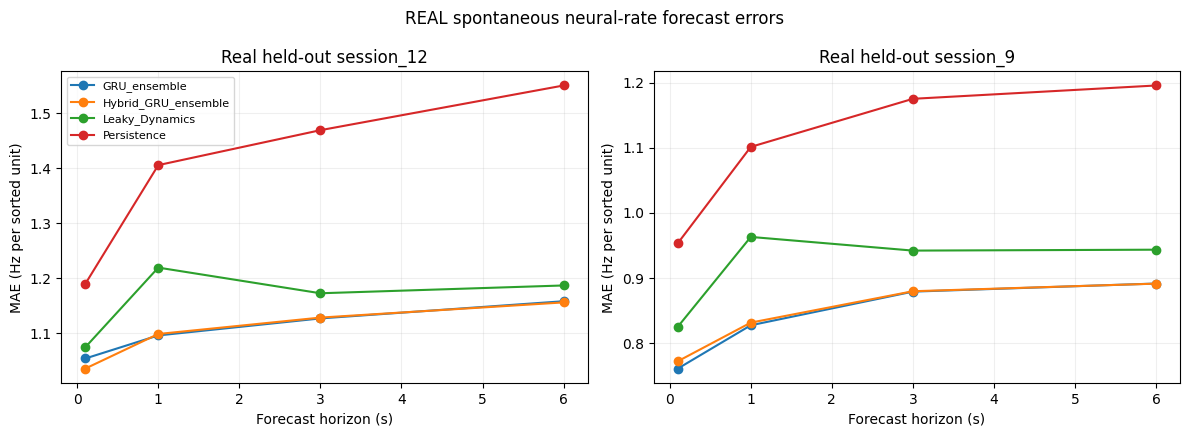

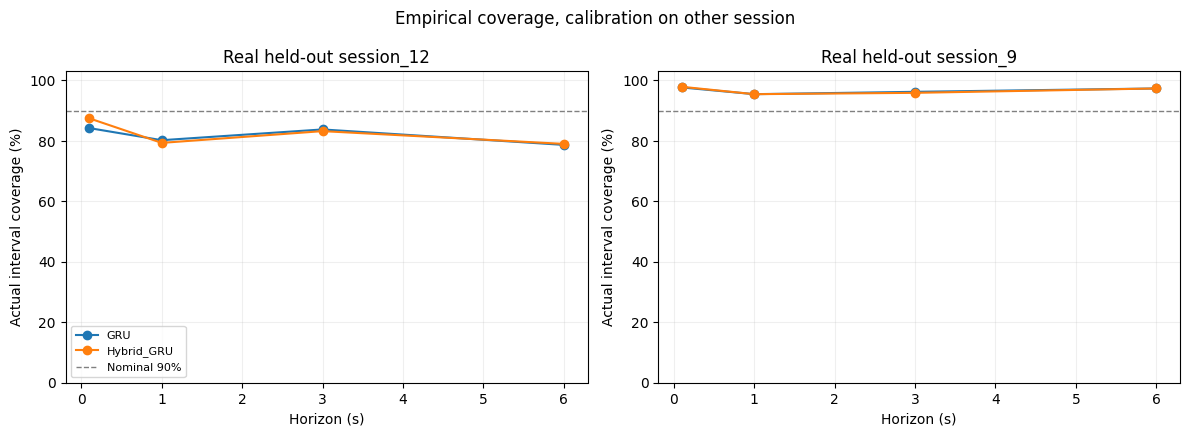

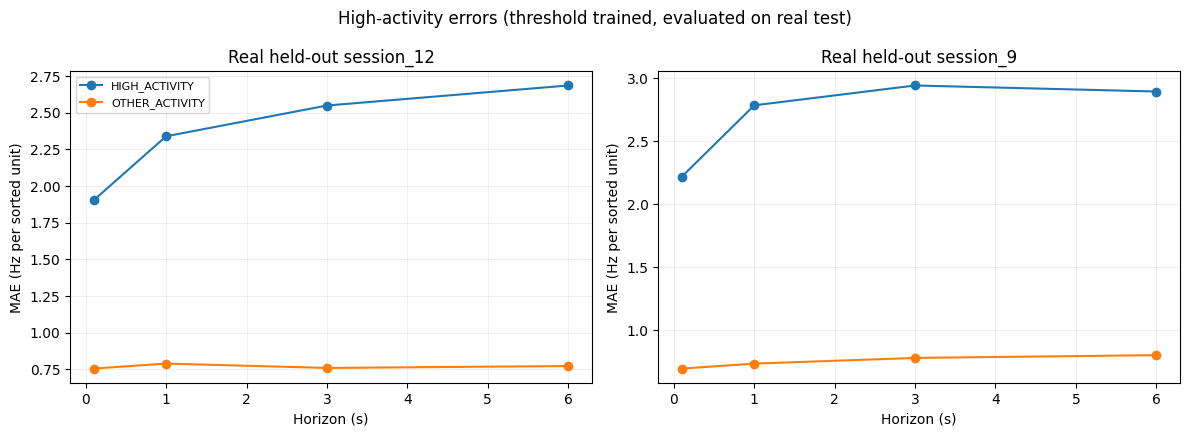

In [9]:
plot_metrics=pd.DataFrame(METRICS).query('group=="ALL"')
fig,axs=plt.subplots(1,2,figsize=(12,4.4),sharey=False)
for ax,(session,part) in zip(axs,plot_metrics.groupby('heldout_session')):
    for model,group in part.groupby('model'):
        d=group.set_index('horizon').reindex(HORIZON_NAMES)
        ax.plot(HORIZONS*BIN_SEC,d.MAE_Hz.to_numpy(),'o-',label=model)
    ax.set_title('Real held-out '+session);ax.set_xlabel('Forecast horizon (s)')
    ax.set_ylabel('MAE (Hz per sorted unit)');ax.grid(alpha=.2)
axs[0].legend(fontsize=8);fig.suptitle('REAL spontaneous neural-rate forecast errors')
fig.tight_layout();fig.savefig(OUT/'fig1_REAL_multihorizon_MAE.png',dpi=170);plt.show()

fig,axs=plt.subplots(1,2,figsize=(12,4.4))
plot_int=interval_df[(interval_df.group=='ALL') & (interval_df.method=='ABSOLUTE_CONFORMAL')]
for ax,(session,part) in zip(axs,plot_int.groupby('test_session')):
    for model,d in part.groupby('model'):
        d=d.set_index('horizon').reindex(HORIZON_NAMES)
        ax.plot(HORIZONS*BIN_SEC,100*d.empirical_coverage.to_numpy(),'o-',label=model)
    ax.axhline(90,ls='--',color='gray',lw=1,label='Nominal 90%')
    ax.set_ylim(0,103);ax.set_xlabel('Horizon (s)');ax.set_ylabel('Actual interval coverage (%)')
    ax.set_title('Real held-out '+session);ax.grid(alpha=.2)
axs[0].legend(fontsize=8);fig.suptitle('Empirical coverage, calibration on other session')
fig.tight_layout();fig.savefig(OUT/'fig2_REAL_uncertainty_interval_coverage.png',dpi=170);plt.show()

peak=pd.DataFrame(METRICS)
peak=peak[(peak.model=='Hybrid_GRU_ensemble') &
          (peak.group.isin(['HIGH_ACTIVITY','OTHER_ACTIVITY']))]
fig,axs=plt.subplots(1,2,figsize=(12,4.4))
for ax,(session,part) in zip(axs,peak.groupby('heldout_session')):
    for grp,d in part.groupby('group'):
        d=d.set_index('horizon').reindex(HORIZON_NAMES)
        ax.plot(HORIZONS*BIN_SEC,d.MAE_Hz,'o-',label=grp)
    ax.set_title('Real held-out '+session);ax.set_xlabel('Horizon (s)')
    ax.set_ylabel('MAE (Hz per sorted unit)');ax.grid(alpha=.2)
axs[0].legend(fontsize=8);fig.suptitle('High-activity errors (threshold trained, evaluated on real test)')
fig.tight_layout();fig.savefig(OUT/'fig3_REAL_high_activity_MAE.png',dpi=170);plt.show()

## 10. Real 6-second free-running rollouts: compounding errors

Direct multi-horizon prediction is evaluated above. Now we separately test **recursive free-running behavior**: starting from 2 seconds of *real* neural history, repeatedly forecast the next 100-ms bin without ever injecting observed future neural rates. Compare persistence, leaky dynamics, GRU ensemble and hybrid ensemble. Rollouts are only sampled from fully light-free intervals.

Mean REAL 6s free-running MAE across sampled light-free segments:
test_session  model              
session_12    GRU_ensemble           1.130
              Hybrid_GRU_ensemble    1.145
              Leaky_Dynamics         1.147
              Persistence            1.467
session_9     GRU_ensemble           0.886
              Hybrid_GRU_ensemble    0.884
              Leaky_Dynamics         0.963
              Persistence            1.088
Name: MAE_Hz, dtype: float64


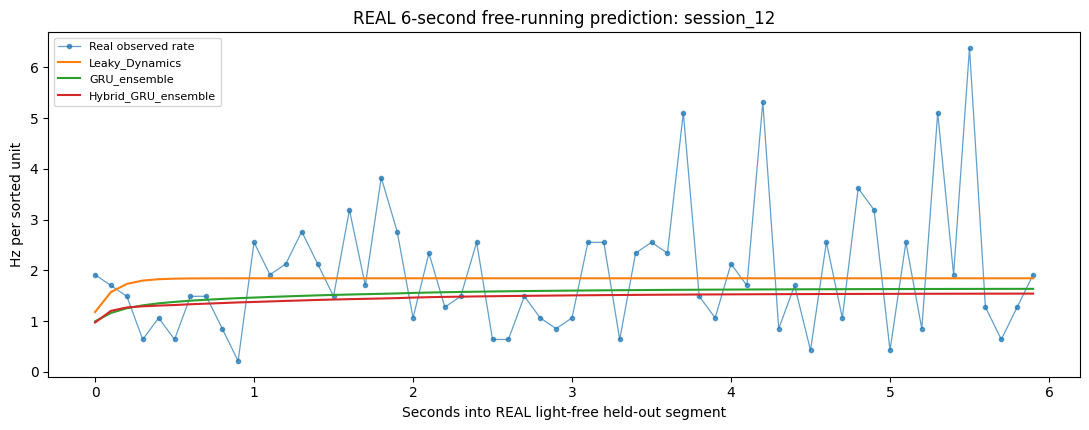

In [10]:
def predict_history_ensembled(history,kind,rec):
    h=np.asarray(history,dtype=np.float32)[None,:]
    fake={'X':h,'last':h[:,-1]}
    info=rec['families'][kind]
    vals=[]
    for model in info['models']:
        sc=info['scaler']
        inp=model_features(fake,sc)
        model=model.to(DEVICE).eval()
        with torch.no_grad():raw=model(torch.from_numpy(inp).to(DEVICE)).cpu().numpy()
        z=raw*np.asarray(sc['target_sd'])+np.asarray(sc['target_mu'])
        if kind=='Hybrid_GRU':z=z+np.log1p(leaky_multihorizon(fake['last'],rec['params']))
        vals.append(np.expm1(np.clip(z,0,np.log1p(500.)))[0,0])
    return float(np.mean(vals))

def free_run(start_history,kind,rec,n_steps=60):
    history=list(np.asarray(start_history,dtype=float))
    out=[]
    for _ in range(n_steps):
        nxt=predict_history_ensembled(history[-HISTORY_BINS:],kind,rec)
        out.append(nxt);history.append(nxt)
    return np.asarray(out)

ROLL_ROWS=[];ROLL_TRAJ=[];first_plot=None
for fold,rec in SAVED.items():
    test=rec['splits']['test'];s=sessions[rec['test_session']]
    rng=np.random.default_rng(SEED+fold)
    possible=test['anchor'].copy();rng.shuffle(possible)
    chosen=[]
    for a in possible:
        if all(abs(int(a)-int(b))>MAX_H+HISTORY_BINS+10 for b in chosen):
            chosen.append(a)
        if len(chosen)>=N_ROLLOUT_SEGMENTS:break
    if not chosen:raise RuntimeError('No eligible held-out free-running rollouts')
    for seg,a in enumerate(sorted(chosen)):
        hist=s['rate'][a-HISTORY_BINS:a]
        y=s['rate'][a:a+60].astype(float)
        leak=[];lv=float(hist[-1])
        for k in range(60):
            lv=float(leaky_multihorizon([lv],rec['params'])[0,0]);leak.append(lv)
        preds={'Persistence':np.full(60,hist[-1]),'Leaky_Dynamics':np.asarray(leak),
               'GRU_ensemble':free_run(hist,'GRU',rec),
               'Hybrid_GRU_ensemble':free_run(hist,'Hybrid_GRU',rec)}
        for name,yp in preds.items():
            for horizon,n_steps in [('1s',10),('3s',30),('6s',60)]:
                ROLL_ROWS.append({'fold':fold,'test_session':rec['test_session'],
                                  'segment':seg,'start_sec':float(a*BIN_SEC),'period':horizon,
                                  'model':name,**metrics(y[:n_steps],yp[:n_steps])})
        for j in range(60):
            row={'fold':fold,'test_session':rec['test_session'],'segment':seg,
                 't_sec':float((a+j)*BIN_SEC),'observed_Hz':float(y[j])}
            for name,yp in preds.items():row[name+'_pred_Hz']=float(yp[j])
            ROLL_TRAJ.append(row)
        if first_plot is None:first_plot=(a,rec['test_session'],y,preds)
roll_metrics=pd.DataFrame(ROLL_ROWS)
roll_metrics.to_csv(OUT/'REAL_heldout_free_running_rollout_metrics.csv',index=False)
pd.DataFrame(ROLL_TRAJ).to_csv(OUT/'REAL_heldout_free_running_trajectories.csv',index=False)
print('Mean REAL 6s free-running MAE across sampled light-free segments:')
print(roll_metrics.query('period=="6s"').groupby(['test_session','model']).MAE_Hz.mean().round(3))
if first_plot is not None:
    a,session,y,preds=first_plot
    fig,ax=plt.subplots(figsize=(11,4.4))
    tt=np.arange(60)*BIN_SEC
    ax.plot(tt,y,'.-',lw=.9,alpha=.7,label='Real observed rate')
    for name in ['Leaky_Dynamics','GRU_ensemble','Hybrid_GRU_ensemble']:
        ax.plot(tt,preds[name],lw=1.5,label=name)
    ax.set_xlabel('Seconds into REAL light-free held-out segment')
    ax.set_ylabel('Hz per sorted unit');ax.set_title('REAL 6-second free-running prediction: '+session)
    ax.legend(fontsize=8);fig.tight_layout()
    fig.savefig(OUT/'fig4_REAL_six_second_free_running_example.png',dpi=170);plt.show()

## 11. Optional simulation sanity checks — **not observed optical-response data**

To keep forward progress on the digital-twin concept, we also exercise an **assumed**, dimensionless optical input. The additive gain `beta` and response time constant `tau` are **illustrative**, never fitted to DANDI intervention outcomes. A correct simulation must remain finite/nonnegative and satisfy the zero-gain / no-action identity. These numbers must **not** be mixed with real predictive metrics in a paper.

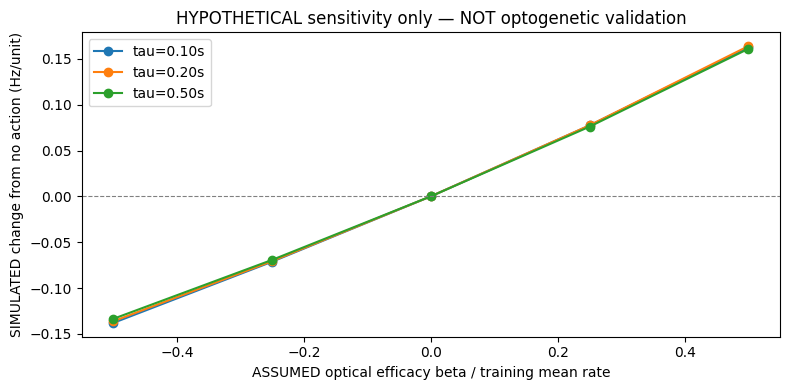

In [11]:
rec=SAVED[1]
initial=rec['splits']['test']['X'][0]
mu=rec['params']['mu_Hz']
N_SIM=60
schedule=np.zeros(N_SIM,dtype=float)
schedule[15:18]=0.5;schedule[24:27]=0.5

def simulated_assumed_light(initial,rec,actions,beta,tau):
    history=list(np.asarray(initial,dtype=float));z=0.;out=[]
    rho=float(np.exp(-BIN_SEC/tau))
    for j,u in enumerate(np.asarray(actions,dtype=float)):
        assert 0<=u<=1
        z=rho*z+(1-rho)*u
        base=predict_history_ensembled(history[-HISTORY_BINS:],'Hybrid_GRU',rec)
        current=float(np.clip(base+beta*z,0,500))
        history.append(current)
        out.append({'sim_sec':j*BIN_SEC,'assumed_action_unitless':float(u),
                    'state_z':float(z),'simulated_rate_Hz':current})
    return pd.DataFrame(out)

reference=simulated_assumed_light(initial,rec,np.zeros(N_SIM),beta=0.,tau=.20)
SENS=[];SCHED=[]
for tau in [.10,.20,.50]:
    for relative in [-.50,-.25,0,.25,.50]:
        beta=float(relative*mu)
        df=simulated_assumed_light(initial,rec,schedule,beta=beta,tau=tau)
        df['assumed_beta_Hz']=beta;df['assumed_tau_sec']=tau
        SCHED.append(df)
        diff=df.simulated_rate_Hz.to_numpy()-reference.simulated_rate_Hz.to_numpy()
        SENS.append({'assumed_tau_sec':tau,'assumed_beta_Hz':beta,
                     'beta_over_training_mu':relative,'mean_simulated_rate_Hz':float(df.simulated_rate_Hz.mean()),
                     'mean_difference_vs_no_action_Hz':float(diff.mean()),
                     'all_finite':bool(np.all(np.isfinite(df.simulated_rate_Hz))),
                     'all_nonnegative':bool(np.all(df.simulated_rate_Hz>=0))})
sens=pd.DataFrame(SENS)
assert sens.all_finite.all() and sens.all_nonnegative.all()
assert np.max(np.abs(sens.query('beta_over_training_mu==0').mean_difference_vs_no_action_Hz))<1e-5
sens.to_csv(OUT/'SIMULATED_assumed_optical_sensitivity_NOT_OBSERVED.csv',index=False)
pd.concat(SCHED,ignore_index=True).to_csv(OUT/'SIMULATED_assumed_optical_trajectories_NOT_OBSERVED.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4))
for tau,d in sens.groupby('assumed_tau_sec'):
    ax.plot(d.beta_over_training_mu,d.mean_difference_vs_no_action_Hz,'o-',label=f'tau={tau:.2f}s')
ax.axhline(0,color='gray',ls='--',lw=.8)
ax.set_xlabel('ASSUMED optical efficacy beta / training mean rate')
ax.set_ylabel('SIMULATED change from no action (Hz/unit)')
ax.set_title('HYPOTHETICAL sensitivity only — NOT optogenetic validation')
ax.legend();fig.tight_layout();fig.savefig(OUT/'fig5_SIMULATED_optical_sensitivity_NOT_OBSERVED.png',dpi=170);plt.show()

## 12. Export, provenance, and decision gate

**What counts as progress?** The hybrid model should improve held-out **real** multi-horizon performance over the GRU; calibrated intervals should have acceptable **empirical held-out coverage at usable widths**; and six-second rollouts should not collapse onto a misleading constant. If the hybrid still loses, carry forward the stronger GRU as the dynamics model. A better interval is not proof of clinically safe stimulation control.

Do not publish numbers from an offline synthetic fixture test. The files named `REAL_*` are generated only from the publicly downloaded NWB data in this notebook.

In [12]:
metadata={
    'phase':'3B - uncertainty-aware hybrid neural digital twin',
    'generated_utc':datetime.now(timezone.utc).isoformat(),
    'DANDI_dandiset':DANDISET,'DANDI_version':VERSION,
    'biological_independence':'same mouse fCamk1, two sessions; no cross-animal replication',
    'target':'Spontaneous neural rate (Hz per sorted unit), light-free history and 6s future',
    'horizon_seconds':(HORIZONS*BIN_SEC).tolist(),
    'ensemble_members_per_model':N_ENSEMBLE,'epochs_max':EPOCHS,
    'calibration':'separate chronological training-session segment, NOT test session',
    'interval_nominal_coverage':1-ALPHA,
    'calibration_warning':'Temporal dependence and session shift invalidate unconditional exchangeability guarantees',
    'free_run_warning':'Recursive neural-rate forecasts trained using direct multi-horizon loss; simulation is not intervention validation',
    'light_simulation':'Assumed beta/tau only. Not fitted to observed DANDI optogenetic effects',
    'research_limitations':[
        'Two held-out sessions represent only one mouse',
        'Optogenetic efficacy and light intensity are not inferred or calibrated',
        'No human epilepsy, seizures, clinical safety, or treatment effect is demonstrated',
        'Empirical predictive interval coverage is not guaranteed under session distribution shift',
        'The leaky model is a simple rate prior, not an identified biophysical neural circuit',
        'Overlapping forecast targets and temporally correlated windows limit effective sample size'
    ]}
(OUT/'STUDY_PROVENANCE_AND_LIMITATIONS.json').write_text(json.dumps(metadata,indent=2))
(OUT/'README_RESULT_INTERPRETATION.txt').write_text(
 'REAL_* and fig1_REAL ... fig4_REAL = predictions on actual DANDI NWB recordings.\n'
 'SIMULATED_* and fig5_SIMULATED = hypothetical optical drive, NOT measured response.\n'
 'All sessions belong to one mouse; cannot claim personalized or clinical generalization.\n'
 '90% is NOMINAL: assess empirical coverage and widths because held-out-session exchangeability is not established.\n')
for req in ['REAL_multihorizon_prediction_metrics.csv','REAL_uncertainty_coverage_and_width.csv',
            'REAL_heldout_free_running_rollout_metrics.csv','REAL_paired_model_improvements_block_CI.csv',
            'STUDY_PROVENANCE_AND_LIMITATIONS.json']:
    assert (OUT/req).exists() and (OUT/req).stat().st_size>0,req
for n in ['REAL_multihorizon_prediction_metrics.csv','REAL_uncertainty_coverage_and_width.csv']:
    d=pd.read_csv(OUT/n)
    assert not d.empty and not d.isnull().all(axis=1).any(),n
zip_path=ROOT/'phase3b_uncertainty_digital_twin_results.zip'
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for path in sorted(OUT.iterdir()):
        if path.is_file():z.write(path,arcname=path.name)
print('SUCCESS — Results ZIP:',zip_path,'size(MB):',round(zip_path.stat().st_size/1e6,2))
print('Ready for post-Kaggle evaluation. Do NOT claim optogenetic treatment efficacy.')

SUCCESS — Results ZIP: /kaggle/working/phase3b_uncertainty_digital_twin_results.zip size(MB): 2.17
Ready for post-Kaggle evaluation. Do NOT claim optogenetic treatment efficacy.


## 13. How to interpret the result

- **If the hybrid consistently beats GRU-only** on held-out sessions and multiple horizons, continue development of the constrained model; otherwise **use the stronger neural predictor**.
- **If nominal 90% intervals under-cover**, report this transparently and improve calibration/shift robustness in Phase 3C. Do not present these intervals as guaranteed safety bounds.
- **If both models flatten high-rate peaks or their six-second rollouts degrade**, a more complex controller will not fix those dynamics by itself.
- **Next phase:** Only if simulation is numerically sound, experiment with *constrained MPC inside the explicitly hypothetical environment*. Never claim observed suppression or human seizure prevention from that test.

**Kaggle:** Run All → download `phase3b_uncertainty_digital_twin_results.zip` under `/kaggle/working/` → upload that ZIP here for a real-data assessment.